In [ ]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------------
# DOWNLOAD THE DATA BEFORE RUNNING THIS NOTEBOOK
# Go to http://tennis-data.co.uk/ and download the yearly .xlsx
# files you want to use (e.g. 2023, 2024, 2025, 2026).
# Place them in the same folder as this notebook, named:
# 2023.xlsx, 2024.xlsx, 2025.xlsx, 2026.xlsx
# ---------------------------------------------------------------

frames = []

for year in [2023, 2024, 2025, 2026]:
    path = f'{year}.xlsx'  
    df_year = pd.read_excel(path)
    df_year['year'] = year  # to track the year 
    frames.append(df_year)
    print(f'{year}: {len(df_year)} matches loaded') 

df = pd.concat(frames, ignore_index=True)
df.head(5) 


2023: 2703 matches loaded
2024: 2703 matches loaded
2025: 2644 matches loaded
2026: 859 matches loaded


,ATP,Location,Tournament,Date,Series,Court,Surface,Round,Best of,Winner,...,B365L,PSW,PSL,MaxW,MaxL,AvgW,AvgL,year,BFEW,BFEL
0,1,Adelaide,Adelaide International 1,2023-01-01,ATP250,Outdoor,Hard,1st Round,3,Giron M.,...,1.91,1.93,1.95,1.99,1.95,1.89,1.89,2023,NaN,NaN
1,1,Adelaide,Adelaide International 1,2023-01-01,ATP250,Outdoor,Hard,1st Round,3,Mcdonald M.,...,3.20,1.39,3.25,1.44,3.40,1.36,3.12,2023,NaN,NaN
2,1,Adelaide,Adelaide International 1,2023-01-02,ATP250,Outdoor,Hard,1st Round,3,Kecmanovic M.,...,2.38,1.58,2.53,1.64,2.53,1.58,2.36,2023,NaN,NaN
3,1,Adelaide,Adelaide International 1,2023-01-02,ATP250,Outdoor,Hard,1st Round,3,Nishioka Y.,...,1.29,4.00,1.28,4.00,1.31,3.56,1.29,2023,NaN,NaN
4,1,Adelaide,Adelaide International 1,2023-01-02,ATP250,Outdoor,Hard,1st Round,3,Popyrin A.,...,1.11,6.20,1.15,6.75,1.18,6.04,1.13,2023,NaN,NaN


In [69]:
# Are years are all present and roughly balanced ?
print(df['year'].value_counts().sort_index())
print()

# Does the date range makes sense ?
print('Earliest match:', df['Date'].min())
print('Latest match:  ', df['Date'].max())

year
2023    2703
2024    2703
2025    2644
2026     859
Name: count, dtype: int64

Earliest match: 2023-01-01 00:00:00
Latest match:   2026-04-12 00:00:00


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8909 entries, 0 to 8908
Data columns (total 39 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ATP         8909 non-null   int64         
 1   Location    8909 non-null   object        
 2   Tournament  8909 non-null   object        
 3   Date        8909 non-null   datetime64[ns]
 4   Series      8909 non-null   object        
 5   Court       8909 non-null   object        
 6   Surface     8909 non-null   object        
 7   Round       8909 non-null   object        
 8   Best of     8909 non-null   int64         
 9   Winner      8909 non-null   object        
 10  Loser       8909 non-null   object        
 11  WRank       8907 non-null   float64       
 12  LRank       8896 non-null   float64       
 13  WPts        8907 non-null   float64       
 14  LPts        8896 non-null   float64       
 15  W1          8844 non-null   float64       
 16  L1          8844 non-nul

In [71]:
print (type(df))

print("df.shape:", df.shape)
print("df.index:", df.index)
print("df.columns:", df.columns)

<class 'pandas.core.frame.DataFrame'>
df.shape: (8909, 39)
df.index: RangeIndex(start=0, stop=8909, step=1)
df.columns: Index(['ATP', 'Location', 'Tournament', 'Date', 'Series', 'Court', 'Surface',
       'Round', 'Best of', 'Winner', 'Loser', 'WRank', 'LRank', 'WPts', 'LPts',
       'W1', 'L1', 'W2', 'L2', 'W3', 'L3', 'W4', 'L4', 'W5', 'L5', 'Wsets',
       'Lsets', 'Comment', 'B365W', 'B365L', 'PSW', 'PSL', 'MaxW', 'MaxL',
       'AvgW', 'AvgL', 'year', 'BFEW', 'BFEL'],
      dtype='object')


In [72]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
ATP,8909.0,30.189247,1.0,16.0,29.0,46.0,65.0,17.633635
Date,8909,2024-07-31 10:21:19.335503360,2023-01-01 00:00:00,2023-09-20 00:00:00,2024-07-16 00:00:00,2025-05-28 00:00:00,2026-04-12 00:00:00,NaN
Best of,8909.0,3.369963,3.0,3.0,3.0,3.0,5.0,0.776609
WRank,8907.0,60.977321,1.0,16.0,43.0,80.0,1187.0,78.056961
LRank,8896.0,94.331947,1.0,35.0,63.0,102.0,4915.0,151.427853
WPts,8907.0,1945.183114,4.0,717.0,1095.0,2370.0,13590.0,2129.856533
LPts,8896.0,1211.521246,1.0,595.75,848.0,1313.5,13590.0,1234.617031
W1,8844.0,5.809815,0.0,6.0,6.0,6.0,7.0,1.239868
L1,8844.0,4.207938,0.0,3.0,4.0,6.0,8.0,1.800982
W2,8781.0,5.767794,0.0,6.0,6.0,6.0,7.0,1.280106


In [73]:
# Check what values appear in the Comment column
print(df['Comment'].value_counts())

# Keep only completed matches (remove retirements and walkovers)
df = df[df['Comment'] == 'Completed'].copy()
print("------------------------")
print("After filtering for completed matches:")
print(df.shape)

Comment
Completed    8574
Retired       268
Walkover       64
Awarded         3
Name: count, dtype: int64
------------------------
After filtering for completed matches:
(8574, 39)


In [74]:
df[['Winner', 'Loser', 'WRank', 'LRank', 'WPts', 'LPts', 
    'AvgW', 'AvgL', 'Surface', 'Series', 'Court', 'Best of', 'Date']].head(5)

,Winner,Loser,WRank,LRank,WPts,LPts,AvgW,AvgL,Surface,Series,Court,Best of,Date
0,Giron M.,Gasquet R.,61.0,68.0,776.0,740.0,1.89,1.89,Hard,ATP250,Outdoor,3,2023-01-01
2,Kecmanovic M.,O Connell C.,29.0,78.0,1420.0,652.0,1.58,2.36,Hard,ATP250,Outdoor,3,2023-01-02
3,Nishioka Y.,Rune H.,36.0,11.0,1134.0,2888.0,3.56,1.29,Hard,ATP250,Outdoor,3,2023-01-02
4,Popyrin A.,Auger-Aliassime F.,120.0,6.0,469.0,4195.0,6.04,1.13,Hard,ATP250,Outdoor,3,2023-01-02
5,Halys Q.,Thompson J.,64.0,84.0,767.0,626.0,2.08,1.74,Hard,ATP250,Outdoor,3,2023-01-02


In [75]:
# everything up to end of 2025 = training
# 2026 matches = test set
# can't use random split bc future matches leak into training

train_df = df[df['year'] <= 2025].copy()
test_df = df[df['year'] == 2026].copy()

print('Train matches:', len(train_df))
print('Test matches: ', len(test_df))

Train matches: 7741
Test matches:  833


In [76]:
# Restructure: each match becomes a row with Player1 vs Player2
def restructure(matches):
    rows = []  

    for _, match in matches.iterrows():
        
        if np.random.rand() > 0.5: # Coin flip heads: Winner becomes Player 1
            r1, r2 = match['WRank'], match['LRank']
            pts1, pts2 = match['WPts'],  match['LPts']
            odd1, odd2 = match['AvgW'],  match['AvgL']
            label = 1  # Player 1 won

        else: # Coin flip tails: Loser becomes Player 1
            r1, r2 = match['LRank'], match['WRank']
            pts1, pts2 = match['LPts'],  match['WPts']
            odd1, odd2 = match['AvgL'],  match['AvgW']
            label = 0  # Player 1 lost
            
        rows.append({
                'date': match['Date'],
                'surface': match['Surface'],
                'series': match['Series'],
                'court': match['Court'],
                'round': match['Round'],
                'best_of': match['Best of'],
                'rank1': r1,
                'rank2': r2,
                'pts1': pts1,
                'pts2': pts2,
                'odd1': odd1,
                'odd2': odd2,
                'label': label
        })
    return pd.DataFrame(rows)

train_data = restructure(train_df)
test_data = restructure(test_df)

print('Train dataset shape:', train_data.shape)
print('Test dataset shape: ', test_data.shape)

Train dataset shape: (7741, 13)
Test dataset shape:  (833, 13)


In [77]:
def build_features(data):
    data = data.copy()
    # Numerical differences
    data['rank_diff'] = data['rank1'] - data['rank2']
    data['pts_diff'] = data['pts1'] - data['pts2']

    # Implied probability from bookmaker odds
    data['implied_prob1'] = 1 / data['odd1']
    data['implied_prob2'] = 1 / data['odd2']
    data['prob_diff'] = data['implied_prob1'] - data['implied_prob2']

    # Make categorical columns into numbers
    data['surface_enc'] = data['surface'].map({'Hard': 0, 'Clay': 1, 'Grass': 2})
    data['series_enc'] = data['series'].map({
        'ATP250': 0, 'ATP500': 1, 'Masters 1000': 2, 'Grand Slam': 3, 'Masters Cup': 4
    })
    data['court_enc'] = data['court'].map({'Outdoor': 0, 'Indoor': 1})
    return data


In [78]:
train_data = build_features(train_data)
test_data  = build_features(test_data) 

# The number of 0 and 1 equal ? Labels balanced ?
print('Train :', train_data['label'].value_counts())
print('Test :', test_data['label'].value_counts())

# Missing values in the features?
FEATURES = ['rank_diff', 'pts_diff', 'prob_diff', 
            'surface_enc', 'series_enc', 'court_enc', 'best_of']

print()
print("Missing values in train:")
print(train_data[FEATURES].isnull().sum())
print()
print("Missing values in test:")
print(test_data[FEATURES].isnull().sum())


Train : label
0    3917
1    3824
Name: count, dtype: int64
Test : label
1    424
0    409
Name: count, dtype: int64

Missing values in train:
rank_diff      14
pts_diff       14
prob_diff       8
surface_enc     0
series_enc      0
court_enc       0
best_of         0
dtype: int64

Missing values in test:
rank_diff      1
pts_diff       1
prob_diff      0
surface_enc    0
series_enc     0
court_enc      0
best_of        0
dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer

# Features and labels
X_train = train_data[FEATURES].astype(np.float32)
y_train = train_data['label']

X_test = test_data[FEATURES].astype(np.float32)
y_test = test_data['label']

# drop missing rows from train 
train_mask = X_train.notna().all(axis=1)
X_train, y_train = X_train[train_mask], y_train[train_mask]

# Impute missing values using the median
imputer = SimpleImputer(strategy='median') 
imputer.fit(X_train) # Calculates the median of each of the 7 feature columns
X_test = pd.DataFrame(imputer.transform(X_test), columns=FEATURES)

print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)

X_train shape: (7720, 7)
X_test shape: (833, 7)


In [80]:
X_train.head()

,rank_diff,pts_diff,prob_diff,surface_enc,series_enc,court_enc,best_of
0,-7.0,36.0,0.000000,0.0,0.0,0.0,3.0
1,49.0,-768.0,-0.209183,0.0,0.0,0.0,3.0
2,25.0,-1754.0,-0.494295,0.0,0.0,0.0,3.0
3,-114.0,3726.0,0.719393,0.0,0.0,0.0,3.0
4,-20.0,141.0,-0.093943,0.0,0.0,0.0,3.0


In [81]:
y_train.head() #just labels

0    1
1    0
2    1
3    0
4    1
Name: label, dtype: int64

In [ ]:
# Decision Tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt = DecisionTreeClassifier(max_depth=3) #Arbitrary value to start.

dt.fit(X_train, y_train) # train model

# Accuracy on both sets
train_acc = accuracy_score(y_true=y_train, y_pred=dt.predict(X_train))
test_acc  = accuracy_score(y_true=y_test,  y_pred=dt.predict(X_test))

print("Train Accuracy: {:.3f} - Test Accuracy: {:.3f}".format(train_acc, test_acc))

Train Accuracy: 0.685 - Test Accuracy: 0.703


[Text(0.5, 0.875, 'prob_diff <= 0.012\ngini = 0.5\nsamples = 7720\nvalue = [3906, 3814]\nclass = P2 wins'),
 Text(0.25, 0.625, 'prob_diff <= -0.36\ngini = 0.431\nsamples = 3961\nvalue = [2717, 1244]\nclass = P2 wins'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'prob_diff <= -0.582\ngini = 0.305\nsamples = 1712\nvalue = [1390, 322]\nclass = P2 wins'),
 Text(0.0625, 0.125, 'gini = 0.187\nsamples = 786\nvalue = [704, 82]\nclass = P2 wins'),
 Text(0.1875, 0.125, 'gini = 0.384\nsamples = 926\nvalue = [686.0, 240.0]\nclass = P2 wins'),
 Text(0.375, 0.375, 'prob_diff <= -0.215\ngini = 0.484\nsamples = 2249\nvalue = [1327, 922]\nclass = P2 wins'),
 Text(0.3125, 0.125, 'gini = 0.46\nsamples = 873\nvalue = [560, 313]\nclass = P2 wins'),
 Text(0.4375, 0.125, 'gini = 0.493\nsamples = 1376\nvalue = [767.0, 609.0]\nclass = P2 wins'),
 Text(0.75, 0.625, 'prob_diff <= 0.325\ngini = 0.433\nsamples = 3759\nvalue = [1189, 2570]\nclass = P1 wins'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375

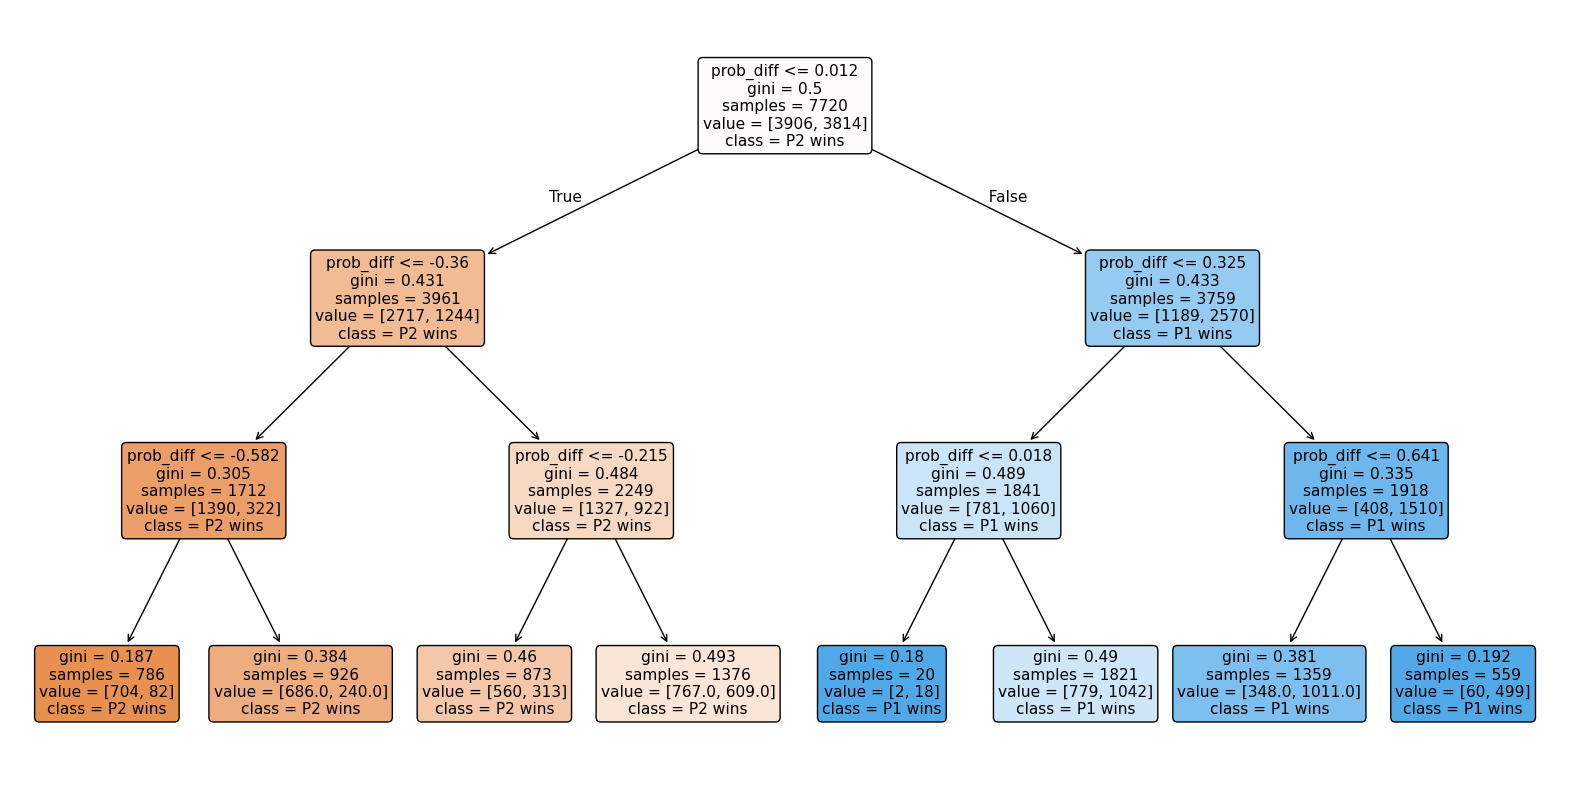

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(dt, ax=ax, # Draw the tree stored inside the model dt onto the axis ax
          feature_names=FEATURES, # tells scikit‑learn how to label each split
          class_names=['P2 wins', 'P1 wins'], #  labels the leaf nodes
          filled=True, rounded=True)

In [ ]:
# Show accuracy of each depth
accuracies = []
for max_depth in range(1, 20): 
    dt = DecisionTreeClassifier(max_depth=max_depth)
    dt.fit(X_train, y_train)

    train_acc = accuracy_score(y_true=y_train, y_pred=dt.predict(X_train))
    test_acc  = accuracy_score(y_true=y_test,  y_pred=dt.predict(X_test))

    print("Max Depth: {:2d} - Train Accuracy: {:.3f} - Test Accuracy: {:.3f}"
          .format(max_depth, train_acc, test_acc))
    accuracies += [[test_acc, max_depth]] # Append pair test accuracy and depth

best_DTaccuracy, best_depth_biased  = max(accuracies)
print("\nBest Depth (Biased): {:2d} - Test Accuracy: {:.3f}".format(best_depth_biased, best_DTaccuracy))

Max Depth:  1 - Train Accuracy: 0.685 - Test Accuracy: 0.703
Max Depth:  2 - Train Accuracy: 0.685 - Test Accuracy: 0.703
Max Depth:  3 - Train Accuracy: 0.685 - Test Accuracy: 0.703
Max Depth:  4 - Train Accuracy: 0.686 - Test Accuracy: 0.702
Max Depth:  5 - Train Accuracy: 0.689 - Test Accuracy: 0.699
Max Depth:  6 - Train Accuracy: 0.696 - Test Accuracy: 0.682
Max Depth:  7 - Train Accuracy: 0.705 - Test Accuracy: 0.691
Max Depth:  8 - Train Accuracy: 0.714 - Test Accuracy: 0.675
Max Depth:  9 - Train Accuracy: 0.729 - Test Accuracy: 0.683
Max Depth: 10 - Train Accuracy: 0.743 - Test Accuracy: 0.661
Max Depth: 11 - Train Accuracy: 0.760 - Test Accuracy: 0.649
Max Depth: 12 - Train Accuracy: 0.781 - Test Accuracy: 0.641
Max Depth: 13 - Train Accuracy: 0.802 - Test Accuracy: 0.625
Max Depth: 14 - Train Accuracy: 0.822 - Test Accuracy: 0.616
Max Depth: 15 - Train Accuracy: 0.840 - Test Accuracy: 0.613
Max Depth: 16 - Train Accuracy: 0.864 - Test Accuracy: 0.600
Max Depth: 17 - Train Ac

In [ ]:
# Split training data further into train / validation for DT
# Fine tune features
split_idx = int(len(X_train) * 0.75)

X_train2 = X_train.iloc[:split_idx]
y_train2 = y_train.iloc[:split_idx]

X_valid  = X_train.iloc[split_idx:]
y_valid  = y_train.iloc[split_idx:]
accuracies = []

for max_depth in range(1, 20):
    dt = DecisionTreeClassifier(max_depth=max_depth)
    dt.fit(X_train2, y_train2)

    train_acc = accuracy_score(y_true=y_train2, y_pred=dt.predict(X_train2))
    test_acc = accuracy_score(y_true=y_valid,  y_pred=dt.predict(X_valid))

    print("Max Depth: {:2d} - Train Accuracy: {:.3f} - Valid Accuracy: {:.3f}"
          .format(max_depth, train_acc, test_acc))

    accuracies += [[test_acc, max_depth]]

best_accuracy, best_depth = max(accuracies)
print("\nBest Depth:", best_depth)

# retrain on full training set with best depth then evaluate on test
dt = DecisionTreeClassifier(max_depth=best_depth)
dt.fit(X_train, y_train)
dt_test_acc = accuracy_score(y_true=y_test, y_pred=dt.predict(X_test))
print("Test Validity After retraining : {:.3f}".format(dt_test_acc))

Max Depth:  1 - Train Accuracy: 0.684 - Valid Accuracy: 0.686
Max Depth:  2 - Train Accuracy: 0.684 - Valid Accuracy: 0.686
Max Depth:  3 - Train Accuracy: 0.685 - Valid Accuracy: 0.686
Max Depth:  4 - Train Accuracy: 0.686 - Valid Accuracy: 0.685
Max Depth:  5 - Train Accuracy: 0.688 - Valid Accuracy: 0.685
Max Depth:  6 - Train Accuracy: 0.692 - Valid Accuracy: 0.684
Max Depth:  7 - Train Accuracy: 0.698 - Valid Accuracy: 0.679
Max Depth:  8 - Train Accuracy: 0.704 - Valid Accuracy: 0.684
Max Depth:  9 - Train Accuracy: 0.717 - Valid Accuracy: 0.667
Max Depth: 10 - Train Accuracy: 0.733 - Valid Accuracy: 0.666
Max Depth: 11 - Train Accuracy: 0.748 - Valid Accuracy: 0.654
Max Depth: 12 - Train Accuracy: 0.764 - Valid Accuracy: 0.646
Max Depth: 13 - Train Accuracy: 0.783 - Valid Accuracy: 0.636
Max Depth: 14 - Train Accuracy: 0.801 - Valid Accuracy: 0.636
Max Depth: 15 - Train Accuracy: 0.817 - Valid Accuracy: 0.634
Max Depth: 16 - Train Accuracy: 0.836 - Valid Accuracy: 0.614
Max Dept

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid_dt = {
    'max_depth':        [2, 3, 4, 5, 6, 7],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion':        ['gini', 'entropy'],
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid_dt, cv=3, scoring='accuracy'
)
grid_dt.fit(X_train, y_train) # train 48 trees

print("Best params:", grid_dt.best_params_)
print("Best CV accuracy: {:.3f}".format(grid_dt.best_score_))

best_dt = grid_dt.best_estimator_
dt_test_acc = accuracy_score(y_test, best_dt.predict(X_test))
print("Test accuracy with best params: {:.3f}".format(dt_test_acc))

Best params: {'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1}
Best CV accuracy: 0.683
Test accuracy with best params: 0.703


Test Accuracy: 0.703


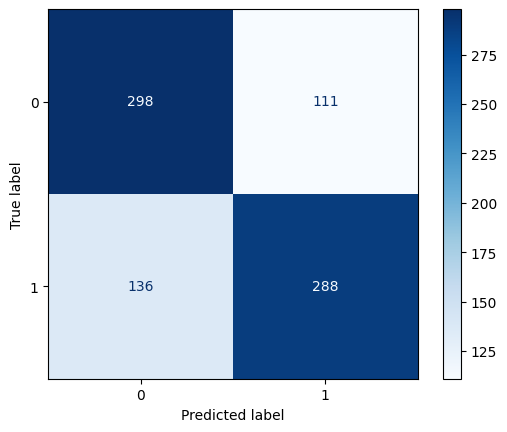

In [87]:
from sklearn.metrics import ConfusionMatrixDisplay

y_pred_dt = best_dt.predict(X_test)

dt_test_acc = accuracy_score(y_true=y_test, y_pred=y_pred_dt)
print("Test Accuracy: {:.3f}".format(dt_test_acc))

ConfusionMatrixDisplay.from_predictions(
    y_true=y_test, y_pred=y_pred_dt, cmap="Blues")

In [ ]:
# LightGBM

import lightgbm as lgb
from sklearn.metrics import accuracy_score

# create the classifier
lgb_model = lgb.LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)

# train the classifier
lgb_model.fit(X_train, y_train)

# compute accuracy on both sets
train_acc = accuracy_score(y_true=y_train, y_pred=lgb_model.predict(X_train))
test_acc  = accuracy_score(y_true=y_test,  y_pred=lgb_model.predict(X_test))

print("Train Accuracy: {:.3f} - Test Accuracy: {:.3f}".format(train_acc, test_acc))

Train Accuracy: 0.770 - Test Accuracy: 0.690


In [ ]:
# Temporal validation split for LightGBM tuning
split_idx = int(len(X_train) * 0.75)
X_train2, y_train2 = X_train.iloc[:split_idx], y_train.iloc[:split_idx]
X_valid,  y_valid  = X_train.iloc[split_idx:], y_train.iloc[split_idx:]

accuracies = []

for n_est in [5, 10, 20, 30, 50, 75, 100]:
    lgb_model = lgb.LGBMClassifier(n_estimators=n_est, random_state=42, verbose=-1)
    lgb_model.fit(X_train2, y_train2)

    train_acc = accuracy_score(y_train2, lgb_model.predict(X_train2))
    val_acc   = accuracy_score(y_valid,  lgb_model.predict(X_valid))

    print("n_estimators: {:4d} - Train Accuracy: {:.3f} - Valid Accuracy: {:.3f}"
          .format(n_est, train_acc, val_acc))

    accuracies += [[val_acc, n_est]]

best_accuracy, best_n_est = max(accuracies)
print("\nBest n_estimators: {:4d} - Valid Accuracy: {:.3f}".format(int(best_n_est), best_accuracy))

# retrain on full training set with best n_estimators found on validation
lgb_final = lgb.LGBMClassifier(n_estimators=int(best_n_est), random_state=42, verbose=-1)
lgb_final.fit(X_train, y_train)

lgb_test_acc = accuracy_score(y_true=y_test, y_pred=lgb_final.predict(X_test))
print("Test Accuracy after retraining: {:.3f}".format(lgb_test_acc))

n_estimators:    5 - Train Accuracy: 0.704 - Valid Accuracy: 0.687
n_estimators:   10 - Train Accuracy: 0.707 - Valid Accuracy: 0.681
n_estimators:   20 - Train Accuracy: 0.717 - Valid Accuracy: 0.683
n_estimators:   30 - Train Accuracy: 0.726 - Valid Accuracy: 0.681
n_estimators:   50 - Train Accuracy: 0.746 - Valid Accuracy: 0.682
n_estimators:   75 - Train Accuracy: 0.770 - Valid Accuracy: 0.676
n_estimators:  100 - Train Accuracy: 0.788 - Valid Accuracy: 0.673

Best n_estimators:    5 - Valid Accuracy: 0.687
Test Accuracy after retraining: 0.702


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators':  [20, 50, 100],
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves':    [15, 31, 63],
}
grid = GridSearchCV(
    lgb.LGBMClassifier(random_state=42, verbose=-1),
    param_grid, cv=3, scoring='accuracy'
)
grid.fit(X_train, y_train) # train 27 models

print("Best params:", grid.best_params_)
print("Best CV accuracy: {:.3f}".format(grid.best_score_))

best_lgb = grid.best_estimator_
lgb_test_acc = accuracy_score(y_test, best_lgb.predict(X_test))
print("Test accuracy with best params: {:.3f}".format(lgb_test_acc))

Best params: {'learning_rate': 0.01, 'n_estimators': 100, 'num_leaves': 15}
Best CV accuracy: 0.682
Test accuracy with best params: 0.707


LightGBM - Test Accuracy: 0.707


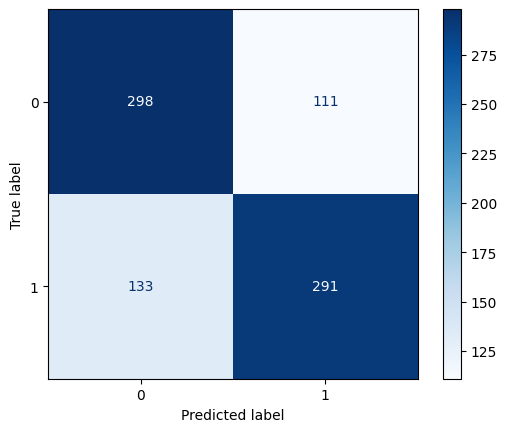

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Retrain with best value found
y_pred_lgb = best_lgb.predict(X_test)

lgb_test_acc = accuracy_score(y_true=y_test, y_pred=y_pred_lgb)
print("LightGBM - Test Accuracy: {:.3f}".format(lgb_test_acc))

ConfusionMatrixDisplay.from_predictions(
    y_true=y_test, y_pred=y_pred_lgb, cmap="Blues")

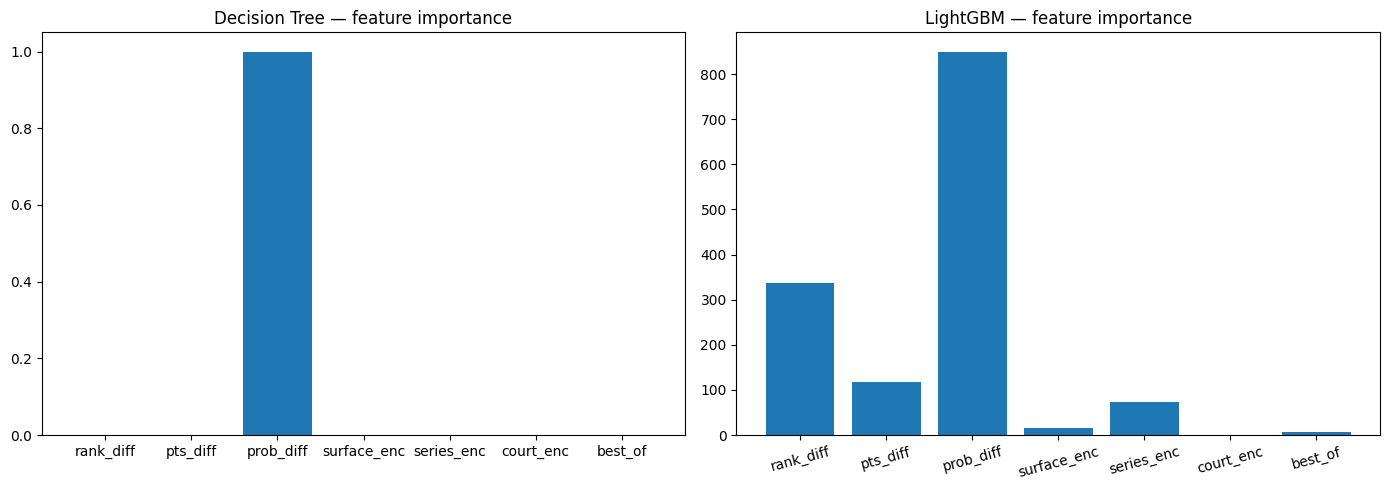

In [ ]:
import matplotlib.pyplot as plt

# Get feature importances from the trained models
importances_dt = best_dt.feature_importances_
importances_lgb = best_lgb.feature_importances_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(FEATURES, importances_dt)
axes[0].set_title("Decision Tree — feature importance")
axes[1].bar(FEATURES, importances_lgb)
axes[1].set_title("LightGBM — feature importance")
plt.xticks(rotation=15) # Make labels readable
plt.tight_layout() # Prevent overlap 

In [93]:
print("Final Model Comparison")
print("-" * 50)
print("Decision Tree (GridSearchCV) - Test Accuracy: {:.3f}".
      format(dt_test_acc))
print("LightGBM (GridSearchCV best) - Test Accuracy: {:.3f}".
      format(accuracy_score(y_test, best_lgb.predict(X_test))))

Final Model Comparison
--------------------------------------------------
Decision Tree (GridSearchCV) - Test Accuracy: 0.703
LightGBM (GridSearchCV best) - Test Accuracy: 0.707


In [94]:
from sklearn.metrics import classification_report, roc_auc_score

print("Decision Tree - Classification Report")
print(classification_report(y_test, best_dt.predict(X_test)))
print("AUC-ROC:", roc_auc_score(y_test, best_dt.predict_proba(X_test)[:, 1]))

Decision Tree - Classification Report
              precision    recall  f1-score   support

           0       0.69      0.73      0.71       409
           1       0.72      0.68      0.70       424

    accuracy                           0.70       833
   macro avg       0.70      0.70      0.70       833
weighted avg       0.70      0.70      0.70       833

AUC-ROC: 0.7499250357521796


In [95]:
from sklearn.metrics import classification_report, roc_auc_score

print("LightGBM - Classification Report")
print(classification_report(y_test, y_pred_lgb))
print("AUC-ROC:", roc_auc_score(y_test, best_lgb.predict_proba(X_test)[:, 1]))

LightGBM - Classification Report
              precision    recall  f1-score   support

           0       0.69      0.73      0.71       409
           1       0.72      0.69      0.70       424

    accuracy                           0.71       833
   macro avg       0.71      0.71      0.71       833
weighted avg       0.71      0.71      0.71       833

AUC-ROC: 0.7648804031923238


In [ ]:
# Error analysis

# Find wrongly predicted matches in test set
test_data_clean = test_data.copy()
test_data_clean['predicted'] = y_pred_lgb
test_data_clean['correct']   = (test_data_clean['predicted'] == test_data_clean['label'])

# Worst predictions
wrong = test_data_clean[test_data_clean['correct'] == False]
print("Wrong predictions by surface:")
print(wrong['surface'].value_counts())
print("\nWrong predictions by series:")
print(wrong['series'].value_counts())

Wrong predictions by surface:
surface
Hard    181
Clay     63
Name: count, dtype: int64

Wrong predictions by series:
series
ATP250          94
Masters 1000    79
ATP500          47
Grand Slam      24
Name: count, dtype: int64


In [ ]:
# Error rate by surface (wrong predictions / total matches of that surface)
total_by_surface = test_data_clean['surface'].value_counts()
wrong_by_surface = wrong['surface'].value_counts()
error_rate_surface = (wrong_by_surface / total_by_surface).sort_values(ascending=False)
print("Error rate by surface:")
print(error_rate_surface)
print()

# Error rate by series
total_by_series = test_data_clean['series'].value_counts()
wrong_by_series = wrong['series'].value_counts()
error_rate_series = (wrong_by_series / total_by_series).sort_values(ascending=False)
print("Error rate by series:")
print(error_rate_series)

Error rate by surface:
surface
Clay    0.297170
Hard    0.291465
Name: count, dtype: float64

Error rate by series:
series
Masters 1000    0.330544
ATP250          0.324138
ATP500          0.255435
Grand Slam      0.200000
Name: count, dtype: float64


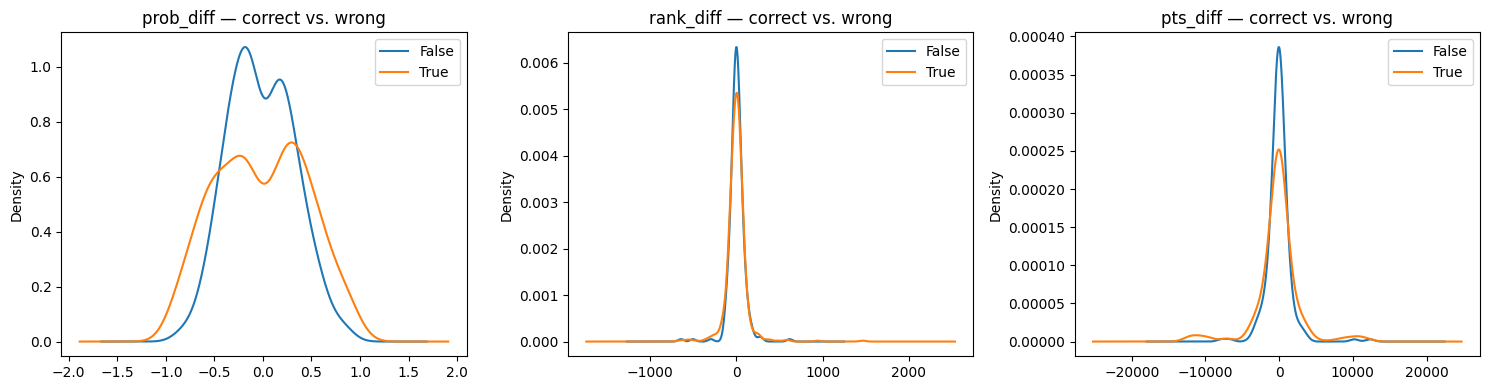

In [98]:
# Feature distributions — correct vs. wrong 

test_data_clean['correct'] = (test_data_clean['predicted'] == test_data_clean['label'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, ['prob_diff', 'rank_diff', 'pts_diff']):
    test_data_clean.groupby('correct')[feat].plot(kind='kde', ax=ax, legend=True)
    ax.set_title(f"{feat} — correct vs. wrong")
plt.tight_layout()

In [99]:
# Most correct predictions analysis

correct = test_data_clean[test_data_clean['correct'] == True]

print("Correct predictions by surface:")
print(correct['surface'].value_counts())
print("\nMean prob_diff — correct:", correct['prob_diff'].abs().mean().round(3),
      " | wrong:", wrong['prob_diff'].abs().mean().round(3))

Correct predictions by surface:
surface
Hard    440
Clay    149
Name: count, dtype: int64

Mean prob_diff — correct: 0.404  | wrong: 0.282


In [ ]:
# compare the model against a baseline 

# Baseline 1: majority class (always predict 1)
majority_acc = max(y_test.mean(), 1 - y_test.mean())
print("Baseline 1 - Majority class accuracy:   {:.3f}".format(majority_acc))

# Baseline 2: always follow the bookmaker (predict 1 if prob_diff > 0)
bookmaker_pred = (test_data.loc[y_test.index, 'prob_diff'] > 0).astype(int)
bookmaker_acc  = accuracy_score(y_test, bookmaker_pred)
print("Baseline 2 - Bookmaker baseline accuracy: {:.3f}".format(bookmaker_acc))

# Models
print()
print("Decision Tree accuracy:  {:.3f}".format(dt_test_acc))
print("LightGBM accuracy:       {:.3f}".format(lgb_test_acc))

# Improvement over bookmaker
print()
print("Improvement over majority class:  +{:.3f}".format(dt_test_acc - majority_acc))
print("Improvement over bookmaker:       +{:.3f}".format(dt_test_acc - bookmaker_acc))

Baseline 1 - Majority class accuracy:   0.509
Baseline 2 - Bookmaker baseline accuracy: 0.707

Decision Tree accuracy:  0.703
LightGBM accuracy:       0.707

Improvement over majority class:  +0.194
Improvement over bookmaker:       +-0.004
